# BLM4800 - Veri Madenciliğine Giriş Dersi Projesi

- Tarık TAŞKIN
- 21011022

### Veri Kümesi

Bu veri kümesi, korteksin nükleer fraksiyonunda saptanabilir sinyaller üreten 77 protein düzeyinden oluşmaktadır.

Toplamda 72 fare bulunmaktadır:
- 38’i kontrol (control)
- 34’ü trizomik (trisomic, Down sendromlu)

Her fare için, her bir proteinden 15 ölçüm alınmıştır:
- Kontrol fareleri: 38 x 15 = 570 ölçüm
- Trizomik fareler: 34 x 15 = 510 ölçüm
- Toplamda: 1080 ölçüm / protein


---

#### Özellikler

Fareler, genotip, davranış ve tedavi gibi özelliklere göre 8 sınıfa ayrılmıştır:

- Genotipe göre:
  - Kontrol (control)
  - Trizomik (trisomic)

- Davranışa göre:
  - Öğrenmeye teşvik edilenler (stimulated to learn, *context-shock*)
  - Teşvik edilmeyenler (not stimulated to learn, *shock-context*)

- Tedaviye göre:
  - Memantin (memantine) adlı ilaçla enjekte edilenler
  - Salin (saline) ile enjekte edilenler

---

#### Sınıflar
| Sınıf Kodu | Açıklama |
|------------|----------|
| `c-CS-s` | Kontrol fareleri, öğrenmeye teşvik edilmiş, salin ile enjekte edilmiş (**9 fare**) |
| `c-CS-m` | Kontrol fareleri, öğrenmeye teşvik edilmiş, memantin ile enjekte edilmiş (**10 fare**) |
| `c-SC-s` | Kontrol fareleri, öğrenmeye teşvik edilmemiş, salin ile enjekte edilmiş (**9 fare**) |
| `c-SC-m` | Kontrol fareleri, öğrenmeye teşvik edilmemiş, memantin ile enjekte edilmiş (**10 fare**) |
| `t-CS-s` | Trizomik fareler, öğrenmeye teşvik edilmiş, salin ile enjekte edilmiş (**7 fare**) |
| `t-CS-m` | Trizomik fareler, öğrenmeye teşvik edilmiş, memantin ile enjekte edilmiş (**9 fare**) |
| `t-SC-s` | Trizomik fareler, öğrenmeye teşvik edilmemiş, salin ile enjekte edilmiş (**9 fare**) |
| `t-SC-m` | Trizomik fareler, öğrenmeye teşvik edilmemiş, memantin ile enjekte edilmiş (**9 fare**) |

In [1]:
import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns

from scipy.stats import mode
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import plot_tree

## Veri Analizi

In [2]:
df = pd.read_excel("Data_Cortex_Nuclear.xls")

In [3]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 500)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1080 entries, 0 to 1079
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   MouseID          1080 non-null   object 
 1   DYRK1A_N         1077 non-null   float64
 2   ITSN1_N          1077 non-null   float64
 3   BDNF_N           1077 non-null   float64
 4   NR1_N            1077 non-null   float64
 5   NR2A_N           1077 non-null   float64
 6   pAKT_N           1077 non-null   float64
 7   pBRAF_N          1077 non-null   float64
 8   pCAMKII_N        1077 non-null   float64
 9   pCREB_N          1077 non-null   float64
 10  pELK_N           1077 non-null   float64
 11  pERK_N           1077 non-null   float64
 12  pJNK_N           1077 non-null   float64
 13  PKCA_N           1077 non-null   float64
 14  pMEK_N           1077 non-null   float64
 15  pNR1_N           1077 non-null   float64
 16  pNR2A_N          1077 non-null   float64
 17  pNR2B_N       

In [5]:
df.columns

Index(['MouseID', 'DYRK1A_N', 'ITSN1_N', 'BDNF_N', 'NR1_N', 'NR2A_N', 'pAKT_N', 'pBRAF_N', 'pCAMKII_N', 'pCREB_N', 'pELK_N', 'pERK_N', 'pJNK_N', 'PKCA_N', 'pMEK_N', 'pNR1_N', 'pNR2A_N', 'pNR2B_N', 'pPKCAB_N', 'pRSK_N', 'AKT_N', 'BRAF_N', 'CAMKII_N', 'CREB_N', 'ELK_N', 'ERK_N', 'GSK3B_N', 'JNK_N', 'MEK_N', 'TRKA_N', 'RSK_N', 'APP_N', 'Bcatenin_N', 'SOD1_N', 'MTOR_N', 'P38_N', 'pMTOR_N', 'DSCR1_N', 'AMPKA_N', 'NR2B_N', 'pNUMB_N', 'RAPTOR_N', 'TIAM1_N', 'pP70S6_N', 'NUMB_N', 'P70S6_N', 'pGSK3B_N',
       'pPKCG_N', 'CDK5_N', 'S6_N', 'ADARB1_N', 'AcetylH3K9_N', 'RRP1_N', 'BAX_N', 'ARC_N', 'ERBB4_N', 'nNOS_N', 'Tau_N', 'GFAP_N', 'GluR3_N', 'GluR4_N', 'IL1B_N', 'P3525_N', 'pCASP9_N', 'PSD95_N', 'SNCA_N', 'Ubiquitin_N', 'pGSK3B_Tyr216_N', 'SHH_N', 'BAD_N', 'BCL2_N', 'pS6_N', 'pCFOS_N', 'SYP_N', 'H3AcK18_N', 'EGR1_N', 'H3MeK4_N', 'CaNA_N', 'Genotype', 'Treatment', 'Behavior', 'class'],
      dtype='object')

In [6]:
df.describe()

,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,pELK_N,pERK_N,pJNK_N,PKCA_N,pMEK_N,pNR1_N,pNR2A_N,pNR2B_N,pPKCAB_N,pRSK_N,AKT_N,BRAF_N,CAMKII_N,CREB_N,ELK_N,ERK_N,GSK3B_N,JNK_N,MEK_N,TRKA_N,RSK_N,APP_N,Bcatenin_N,SOD1_N,MTOR_N,P38_N,pMTOR_N,DSCR1_N,AMPKA_N,NR2B_N,pNUMB_N,RAPTOR_N,TIAM1_N,pP70S6_N,NUMB_N,P70S6_N,pGSK3B_N,pPKCG_N,CDK5_N,S6_N,ADARB1_N,AcetylH3K9_N,RRP1_N,BAX_N,ARC_N,ERBB4_N,nNOS_N,Tau_N,GFAP_N,GluR3_N,GluR4_N,IL1B_N,P3525_N,pCASP9_N,PSD95_N,SNCA_N,Ubiquitin_N,pGSK3B_Tyr216_N,SHH_N,BAD_N,BCL2_N,pS6_N,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N
count,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1062.000000,1077.000000,1077.000000,1077.000000,1073.000000,1077.000000,1077.000000,1077.000000,1062.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1077.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,1080.000000,867.000000,795.000000,1080.000000,1005.000000,1080.000000,900.000000,870.000000,810.000000,1080.000000
mean,0.425810,0.617102,0.319088,2.297269,3.843934,0.233168,0.181846,3.537109,0.212574,1.428682,0.545904,0.313505,0.317939,0.275033,0.825813,0.726933,1.561965,1.525338,0.442848,0.682236,0.378519,0.363357,0.180492,1.173400,2.474492,1.172603,0.241644,0.272789,0.693180,0.168417,0.404808,2.146550,0.542635,0.452459,0.415311,0.759047,0.585186,0.368370,0.565317,0.357095,0.315813,0.418605,0.394475,0.181080,0.943116,0.161211,1.706599,0.292434,0.429226,1.197420,0.216482,0.166631,0.179307,0.121521,0.156478,0.181300,0.210489,0.120889,0.221851,0.126560,0.527349,0.291276,1.548348,2.235236,0.159821,1.239270,0.848767,0.226676,0.157914,0.134762,0.121521,0.131053,0.446073,0.169609,0.183135,0.205440,1.337784
std,0.249362,0.251640,0.049383,0.347293,0.933100,0.041634,0.027042,1.295169,0.032587,0.466904,0.345309,0.051978,0.052236,0.046164,0.117969,0.188013,0.270737,0.481780,0.066672,0.127434,0.216388,0.052352,0.026370,0.335786,0.653397,0.244752,0.033901,0.041075,0.120825,0.028138,0.061173,0.435742,0.280568,0.065488,0.089290,0.122446,0.100601,0.062583,0.088201,0.063025,0.054163,0.067288,0.156170,0.029296,0.172838,0.019308,0.578442,0.037380,0.137440,0.361743,0.185309,0.031896,0.018826,0.014276,0.015071,0.024919,0.069010,0.013233,0.034886,0.026885,0.082057,0.030015,0.248132,0.254395,0.024150,0.173580,0.094311,0.028989,0.029537,0.027417,0.014276,0.023863,0.066432,0.059402,0.040406,0.055514,0.317126
min,0.145327,0.245359,0.115181,1.330831,1.737540,0.063236,0.064043,1.343998,0.112812,0.429032,0.149155,0.052110,0.191431,0.056818,0.500160,0.281285,0.301609,0.567840,0.095942,0.064421,0.143894,0.212960,0.113636,0.497695,1.131796,0.151124,0.046298,0.147201,0.198743,0.107394,0.235595,1.134886,0.217120,0.201143,0.227880,0.166579,0.155321,0.226409,0.184785,0.185598,0.194824,0.237777,0.131120,0.117999,0.344120,0.099976,0.598767,0.181157,0.130206,0.529108,0.052528,-0.062008,0.072326,0.067254,0.100217,0.099734,0.096233,0.086114,0.111382,0.072580,0.284001,0.207438,0.853176,1.206098,0.101233,0.750664,0.577397,0.155869,0.088305,0.080657,0.067254,0.085419,0.258626,0.079691,0.105537,0.101787,0.586479
25%,0.288121,0.473361,0.287444,2.057411,3.155678,0.205755,0.164595,2.479834,0.190823,1.203665,0.337405,0.281242,0.281829,0.244287,0.743491,0.590303,1.381288,1.168258,0.404144,0.596816,0.264334,0.330859,0.161830,0.944435,1.991756,1.023134,0.220400,0.247096,0.617074,0.149622,0.366339,1.826707,0.319639,0.410389,0.351992,0.683501,0.530881,0.326621,0.514892,0.312766,0.276127,0.371976,0.281090,0.

In [7]:
df.head()

,MouseID,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,pELK_N,pERK_N,pJNK_N,PKCA_N,pMEK_N,pNR1_N,pNR2A_N,pNR2B_N,pPKCAB_N,pRSK_N,AKT_N,BRAF_N,CAMKII_N,CREB_N,ELK_N,ERK_N,GSK3B_N,JNK_N,MEK_N,TRKA_N,RSK_N,APP_N,Bcatenin_N,SOD1_N,MTOR_N,P38_N,pMTOR_N,DSCR1_N,AMPKA_N,NR2B_N,pNUMB_N,RAPTOR_N,TIAM1_N,pP70S6_N,NUMB_N,P70S6_N,pGSK3B_N,pPKCG_N,CDK5_N,S6_N,ADARB1_N,AcetylH3K9_N,RRP1_N,BAX_N,ARC_N,ERBB4_N,nNOS_N,Tau_N,GFAP_N,GluR3_N,GluR4_N,IL1B_N,P3525_N,pCASP9_N,PSD95_N,SNCA_N,Ubiquitin_N,pGSK3B_Tyr216_N,SHH_N,BAD_N,BCL2_N,pS6_N,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N,Genotype,Treatment,Behavior,class
0,309_1,0.503644,0.747193,0.430175,2.816329,5.990152,0.218830,0.177565,2.373744,0.232224,1.750936,0.687906,0.306382,0.402698,0.296927,1.022060,0.605673,1.877684,2.308745,0.441599,0.859366,0.416289,0.369608,0.178944,1.866358,3.685247,1.537227,0.264526,0.319677,0.813866,0.165846,0.453910,3.037621,0.369510,0.458539,0.335336,0.825192,0.576916,0.448099,0.586271,0.394721,0.339571,0.482864,0.294170,0.182150,0.842725,0.192608,1.443091,0.294700,0.354605,1.339070,0.170119,0.159102,0.188852,0.106305,0.144989,0.176668,0.125190,0.115291,0.228043,0.142756,0.430957,0.247538,1.603310,2.014875,0.108234,1.044979,0.831557,0.188852,0.122652,NaN,0.106305,0.108336,0.427099,0.114783,0.131790,0.128186,1.675652,Control,Memantine,C/S,c-CS-m
1,309_2,0.514617,0.689064,0.411770,2.789514,5.685038,0.211636,0.172817,2.292150,0.226972,1.596377,0.695006,0.299051,0.385987,0.281319,0.956676,0.587559,1.725774,2.043037,0.445222,0.834659,0.400364,0.356178,0.173680,1.761047,3.485287,1.509249,0.255727,0.304419,0.780504,0.157194,0.430940,2.921882,0.342279,0.423560,0.324835,0.761718,0.545097,0.420876,0.545097,0.368255,0.321959,0.454519,0.276431,0.182086,0.847615,0.194815,1.439460,0.294060,0.354548,1.306323,0.171427,0.158129,0.184570,0.106592,0.150471,0.178309,0.134275,0.118235,0.238073,0.142037,0.457156,0.257632,1.671738,2.004605,0.109749,1.009883,0.849270,0.200404,0.116682,NaN,0.106592,0.104315,0.441581,0.111974,0.135103,0.131119,1.743610,Control,Memantine,C/S,c-CS-m
2,309_3,0.509183,0.730247,0.418309,2.687201,5.622059,0.209011,0.175722,2.283337,0.230247,1.561316,0.677348,0.291276,0.381002,0.281710,1.003635,0.602449,1.731873,2.017984,0.467668,0.814329,0.399847,0.368089,0.173905,1.765544,3.571456,1.501244,0.259614,0.311747,0.785154,0.160895,0.423187,2.944136,0.343696,0.425005,0.324852,0.757031,0.543620,0.404630,0.552994,0.363880,0.313086,0.447197,0.256648,0.184388,0.856166,0.200737,1.524364,0.301881,0.386087,1.279600,0.185456,0.148696,0.190532,0.108303,0.145330,0.176213,0.132560,0.117760,0.244817,0.142445,0.510472,0.255343,1.663550,2.016831,0.108196,0.996848,0.846709,0.193685,0.118508,NaN,0.108303,0.106219,0.435777,0.111883,0.133362,0.127431,1.926427,Control,Memantine,C/S,c-CS-m
3,309_4,0.442107,0.617076,0.358626,2.466947,4.979503,0.222886,0.176463,2.152301,0.207004,1.595086,0.583277,0.296729,0.377087,0.313832,0.875390,0.520293,1.566852,2.132754,0.477671,0.727705,0.385639,0.362970,0.179449,1.286277,2.970137,1.419710,0.259536,0.279218,0.734492,0.162210,0.410615,2.500204,0.344509,0.429211,0.330121,0.746980,0.546763,0.386860,0.547849,0.366771,0.328492,0.442650,0.398534,0.161768,0.760234,0.184169,1.612382,0.296382,0.290680,1.198765,0.159799,0.166112,0.185323,0.103184,0.140656,0.163804,0.123210,0.117439,0.234947,0.145068,0.430996,0.251103,1.484624,1.957233,0.119883,0.990225,0.833277,0.192112,0.132781,NaN,0.103184,0.111262,0.391691,0.130405,0.147444,0.146901,1.700563,Control,Memantine,C/S,c-CS-m
4,309_5,0.434940,0.617430,0.358802,2.365785,4.718679,0.213106,0.173627,2.134014,0.192158,1.504230,0.550960,0.286961,0.363502,0.277964,0.864912,0.507990,1.480059,2.013697,0.483416,0.687794,0.367531,0.355311,0.174836,1.324695,2.896334,1.359876,0.250705,0.273667,0.702699,0.154827,0.398550,2.456560,0.329126,0.408755,0.313415,0.691956,0.536860,0.360816,0.512824,0.351551,0.312206,0.419095,0.393447,0.160200,0.768113,0.185718,1.645807,0.296829,0.309345,1.206995,0.164650,0.

In [8]:
# 'Genotype', 'Treatment' ve 'Behavior' sütunları 'class' etiketini oluşturduğu için silinir.
# 'MouseID' sınıflandırmada ve kümelemede bir anlam ifade etmediği için silinir.
df = df.drop(columns=["MouseID", "Genotype", "Treatment", "Behavior"])

In [9]:
df.shape

(1080, 78)

In [10]:
# Her sınıfa düşen örnek sayısı
df["class"].value_counts()

class
c-CS-m    150
c-SC-m    150
c-CS-s    135
c-SC-s    135
t-CS-m    135
t-SC-m    135
t-SC-s    135
t-CS-s    105
Name: count, dtype: int64

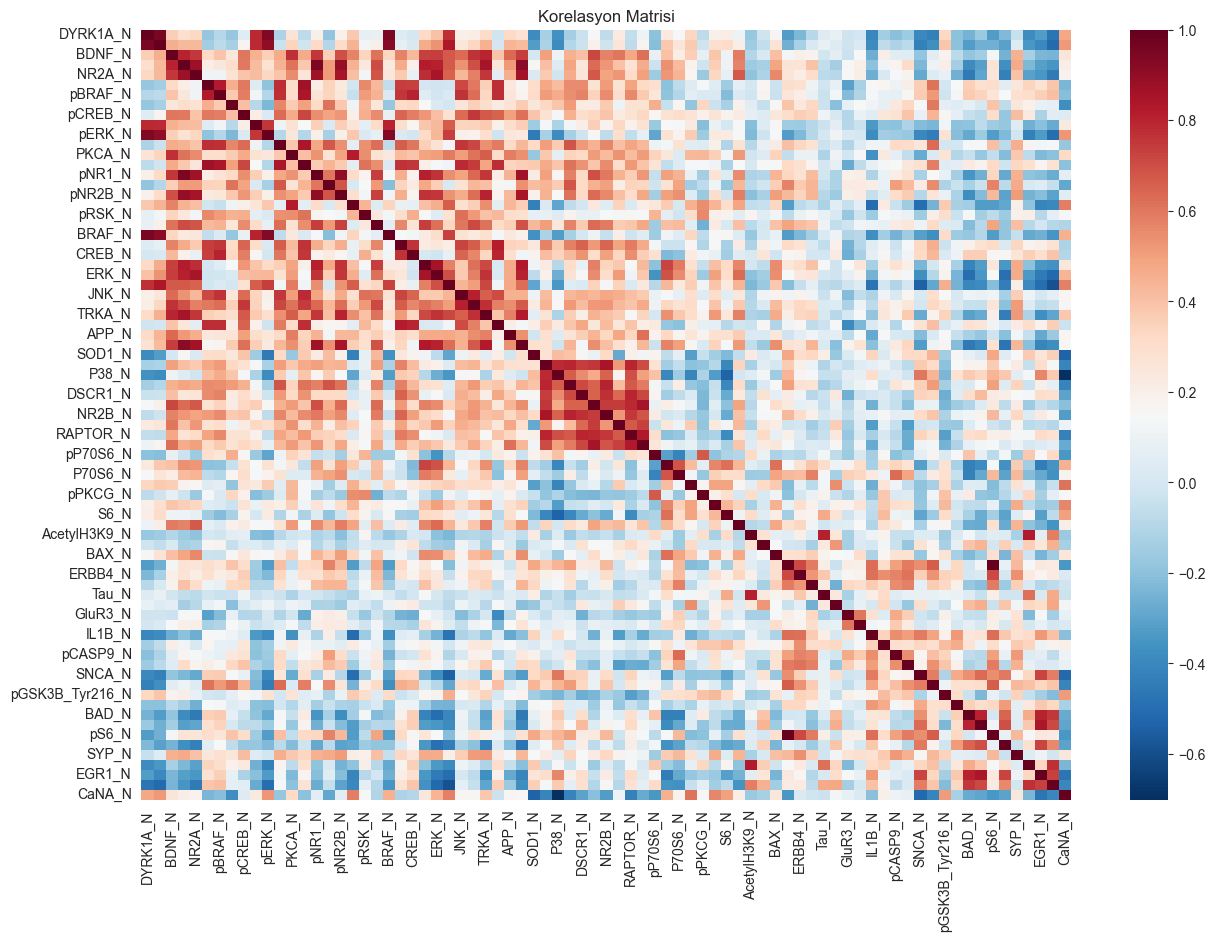

In [11]:
# Korelasyon Matrisi
num_cols = df.select_dtypes(include=['float']).columns
numdf = df[num_cols]
corr_matrix = numdf.corr()

plt.figure(figsize=(15,10))
plt.title('Korelasyon Matrisi')
ax = sns.heatmap(corr_matrix, cmap='RdBu_r')
plt.show()

### Aykırı Değer Analizi

In [12]:
# Fonksiyonlar

# Dataframe'in ilgili sütunun alt ve üst limitlerini bulur.
def outlier_thresholds(dataframe, col_name, q1=0.25, q3=0.75):
    quartile1 = dataframe[col_name].quantile(q1)
    quartile3 = dataframe[col_name].quantile(q3)
    interquantile_range = quartile3 - quartile1
    up_limit = quartile3 + 1.5 * interquantile_range
    low_limit = quartile1 - 1.5 * interquantile_range
    return low_limit, up_limit

# Dataframe'deki aykırı değer içeren sütunları bulur.
def check_outlier(dataframe):
    num_cols = dataframe.select_dtypes(include=['float']).columns
    outlier_cols = []
    for col_name in num_cols:
        low_limit, up_limit = outlier_thresholds(dataframe, col_name)
        if dataframe[(dataframe[col_name] > up_limit) | (dataframe[col_name] < low_limit)].any(axis=None):
            outlier_cols.append(col_name)
    return outlier_cols

# Dataframe'deki aykırı değerleri alt ve üst limit ile doldurur.
def replace_with_thresholds(dataframe):
    num_cols = dataframe.select_dtypes(include=['float']).columns
    for col_name in num_cols:
        low_limit, up_limit = outlier_thresholds(dataframe, col_name)
        dataframe.loc[(dataframe[col_name] < low_limit), col_name] = low_limit
        dataframe.loc[(dataframe[col_name] > up_limit), col_name] = up_limit

In [13]:
num_cols = df.select_dtypes(include=['float']).columns

outlier_cols = check_outlier(df)
print("Aykırı değer içeren sütun sayısı:", len(outlier_cols))

Aykırı değer içeren sütun sayısı: 74


In [14]:
print(outlier_cols)

['DYRK1A_N', 'ITSN1_N', 'BDNF_N', 'NR1_N', 'NR2A_N', 'pAKT_N', 'pBRAF_N', 'pCREB_N', 'pELK_N', 'pERK_N', 'pJNK_N', 'PKCA_N', 'pMEK_N', 'pNR1_N', 'pNR2A_N', 'pNR2B_N', 'pPKCAB_N', 'pRSK_N', 'AKT_N', 'BRAF_N', 'CAMKII_N', 'CREB_N', 'ELK_N', 'ERK_N', 'GSK3B_N', 'JNK_N', 'MEK_N', 'TRKA_N', 'RSK_N', 'APP_N', 'Bcatenin_N', 'SOD1_N', 'MTOR_N', 'P38_N', 'pMTOR_N', 'DSCR1_N', 'AMPKA_N', 'NR2B_N', 'pNUMB_N', 'RAPTOR_N', 'TIAM1_N', 'pP70S6_N', 'NUMB_N', 'P70S6_N', 'pGSK3B_N', 'pPKCG_N', 'CDK5_N', 'ADARB1_N', 'AcetylH3K9_N', 'RRP1_N', 'BAX_N', 'ARC_N', 'ERBB4_N', 'nNOS_N', 'Tau_N', 'GFAP_N', 'GluR3_N', 'GluR4_N', 'IL1B_N', 'P3525_N', 'pCASP9_N', 'PSD95_N', 'SNCA_N', 'Ubiquitin_N', 'pGSK3B_Tyr216_N', 'SHH_N', 'BAD_N', 'BCL2_N', 'pS6_N', 'pCFOS_N', 'SYP_N', 'H3AcK18_N', 'EGR1_N', 'H3MeK4_N']


In [15]:
# Aykırı değerleri alt ve üst limitler ile doldur
replace_with_thresholds(df)

outlier_cols = check_outlier(df)
print("Son durumda aykırı değer içeren sütun sayısı:", len(outlier_cols))

Son durumda aykırı değer içeren sütun sayısı: 0


### Eksik Değer Analizi

In [16]:
print("Toplam eksik değer sayısı:", df.isnull().sum().sum())

Toplam eksik değer sayısı: 1396


In [17]:
# Sütunlara göre eksik değer sayısı
na_columns = [col for col in df.columns if df[col].isnull().sum() > 0]

n_miss = df[na_columns].isnull().sum().sort_values(ascending=False)
ratio = (df[na_columns].isnull().sum() / df.shape[0] * 100).sort_values(ascending=False)
missing_df = pd.concat([n_miss, np.round(ratio, 2)], axis=1, keys=['n_miss', 'ratio'])
print(missing_df)

            n_miss  ratio
BCL2_N         285  26.39
H3MeK4_N       270  25.00
BAD_N          213  19.72
EGR1_N         210  19.44
H3AcK18_N      180  16.67
pCFOS_N         75   6.94
ELK_N           18   1.67
Bcatenin_N      18   1.67
MEK_N            7   0.65
P38_N            3   0.28
TRKA_N           3   0.28
RSK_N            3   0.28
APP_N            3   0.28
SOD1_N           3   0.28
MTOR_N           3   0.28
AMPKA_N          3   0.28
pMTOR_N          3   0.28
DSCR1_N          3   0.28
GSK3B_N          3   0.28
NR2B_N           3   0.28
pNUMB_N          3   0.28
RAPTOR_N         3   0.28
TIAM1_N          3   0.28
pP70S6_N         3   0.28
JNK_N            3   0.28
DYRK1A_N         3   0.28
ITSN1_N          3   0.28
pJNK_N           3   0.28
BDNF_N           3   0.28
NR1_N            3   0.28
NR2A_N           3   0.28
pAKT_N           3   0.28
pBRAF_N          3   0.28
pCAMKII_N        3   0.28
pCREB_N          3   0.28
pELK_N           3   0.28
pERK_N           3   0.28
PKCA_N      

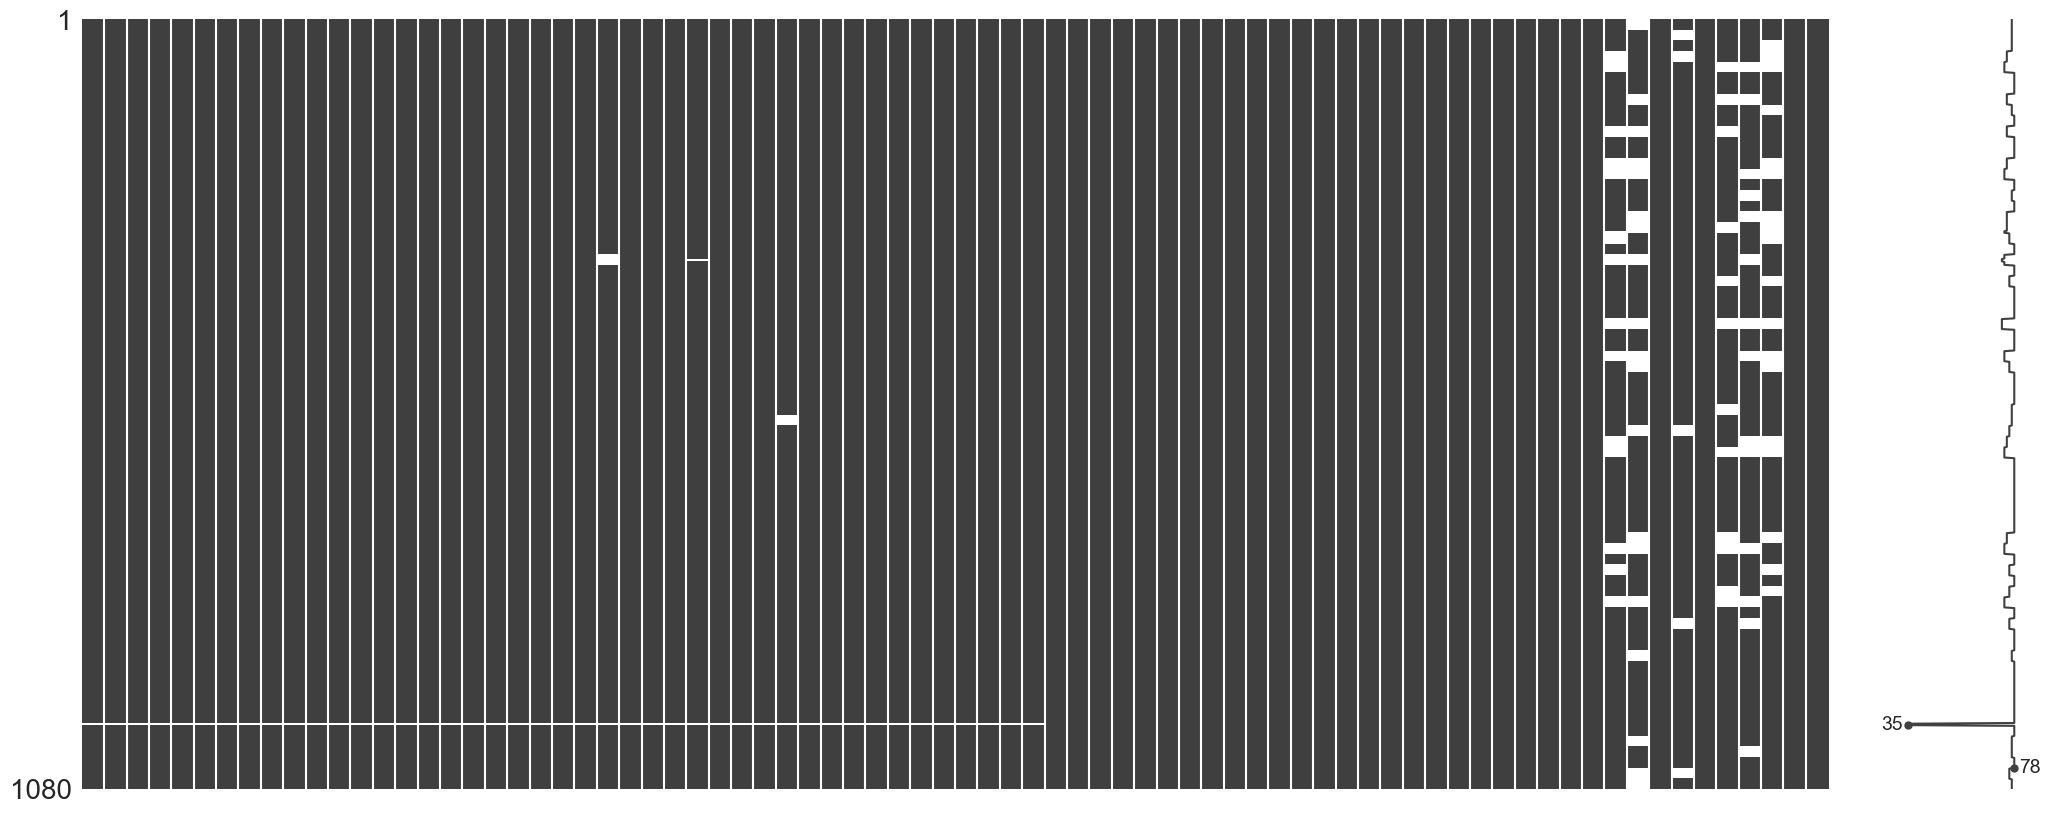

In [18]:
# Eksik değer matrisi
msno.matrix(df)
plt.show()

In [19]:
# %10'dan fazlası eksik olan sütunlar silinir.
df = df.dropna(axis=1,thresh=df.shape[0]*0.9)

In [20]:
print("Güncel eksik değer sayısı:", df.isnull().sum().sum())

Güncel eksik değer sayısı: 238


In [21]:
# Eksik değerleri sınıf ortalamalarıyla doldurulur.
na_columns = [col for col in df.columns if df[col].isnull().sum() > 0]

for column in na_columns:
    df[column] = df.groupby("class")[column].transform(lambda x: x.fillna(x.mean()))

In [22]:
print("Son durumda eksik değer sayısı:", df.isnull().sum().sum())

Son durumda eksik değer sayısı: 0


### Standartlaştırma

Protein ölçümleri farklı ölçeklerde olabileceği için, tüm sayısal değişkenler Min-Max normalizasyonu ile [0, 1] aralığına dönüştürülmüştür. Bu, özellikle KMeans ve DBSCAN gibi mesafeye duyarlı algoritmalar için gereklidir.

In [23]:
num_cols = df.select_dtypes(include=['float']).columns

mms = MinMaxScaler()
df[num_cols] = mms.fit_transform(df[num_cols])

### Temel Bileşen Analizi

NOT: Temel bileşen analizi yapılmış ama sınıflandırmada öznitelik önemlerinin belirlenebilmesi için kullanılmamıştır.

In [24]:
pca = PCA()
pca_fit = pca.fit_transform(df[num_cols])

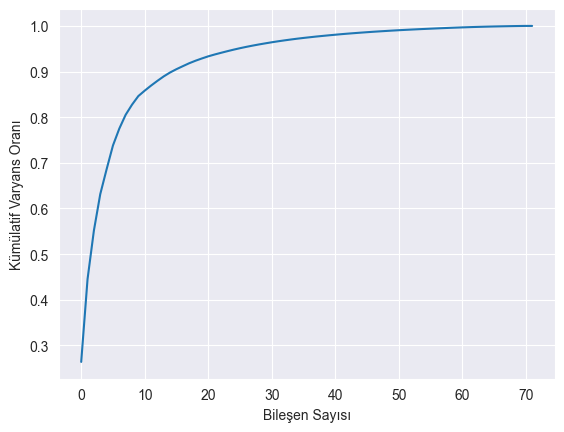

In [25]:
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel("Bileşen Sayısı")
plt.ylabel("Kümülatif Varyans Oranı")
plt.show()

In [26]:
pca = PCA(n_components=0.95)
pca_fit = pca.fit_transform(df[num_cols])
print(pca.n_components_)

26


## Modeller

In [27]:
reports = {}

In [28]:
y = df["class"]
X = df[num_cols]

# %70 eğitim, %30 test kümesi olacak şekilde ayırılır.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=27)

In [29]:
# Fonksiyonlar

# Model öznitelik önem değerlerini görselleştirir.
def plot_importance(model, features):
    if hasattr(model, 'feature_importances_'):
        importance = model.feature_importances_
    elif hasattr(model, 'coef_'):
        importance = np.abs(model.coef_[0])
    else:
        raise AttributeError("Model öznitelik önem değerlerine sahip değil")

    feature_imp = pd.DataFrame({
        'Value': importance,
        'Feature': features.columns
    })

    feature_imp = feature_imp.sort_values('Value', ascending=False)

    plt.figure(figsize=(10, 10))
    sns.set(font_scale=1)
    sns.barplot(data=feature_imp, x='Value', y='Feature')
    plt.title('Özniteliklerin Önemi')

class_labels = sorted(df["class"].unique())

# Karmaşıklık matrisini görselleştirir.
def plot_confusion_matrix(y_true, y_pred, labels=class_labels):
    acc = round(accuracy_score(y_true, y_pred), 2)
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt=".0f", xticklabels=labels, yticklabels=labels, cmap="Blues")
    plt.xlabel('y_pred')
    plt.ylabel('y_test')
    plt.title(f'Accuracy Score: {acc}')
    plt.tight_layout()
    plt.show()

# Kümeleme sonucunu görselleştirir.
def plot_pca_2D(X, y):
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X)

    plt.figure(figsize=(8,6))
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette="Set1", legend="full")
    plt.title("Kümeleme Sonucu")
    plt.xlabel("PCA-1")
    plt.ylabel("PCA-2")
    plt.legend(title="Sınıf")
    plt.tight_layout()
    plt.show()

### Random Forest

In [30]:
rf_model = RandomForestClassifier(n_estimators=20, random_state=23).fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

reports["Random Forest"] = classification_report(y_test, y_pred, output_dict=True)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      c-CS-m       0.90      0.86      0.88        43
      c-CS-s       0.97      0.93      0.95        42
      c-SC-m       0.95      0.98      0.96        55
      c-SC-s       1.00      1.00      1.00        39
      t-CS-m       0.91      0.97      0.94        33
      t-CS-s       1.00      0.97      0.98        30
      t-SC-m       0.98      0.98      0.98        43
      t-SC-s       0.97      1.00      0.99        39

    accuracy                           0.96       324
   macro avg       0.96      0.96      0.96       324
weighted avg       0.96      0.96      0.96       324



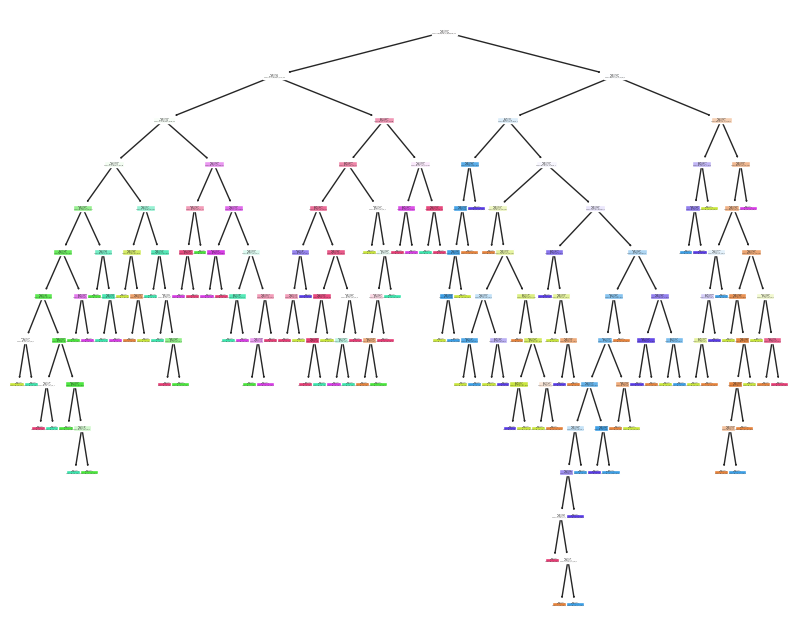

In [31]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(10, 8))
plot_tree(rf_model.estimators_[0], filled=True, ax=axes)
plt.show()

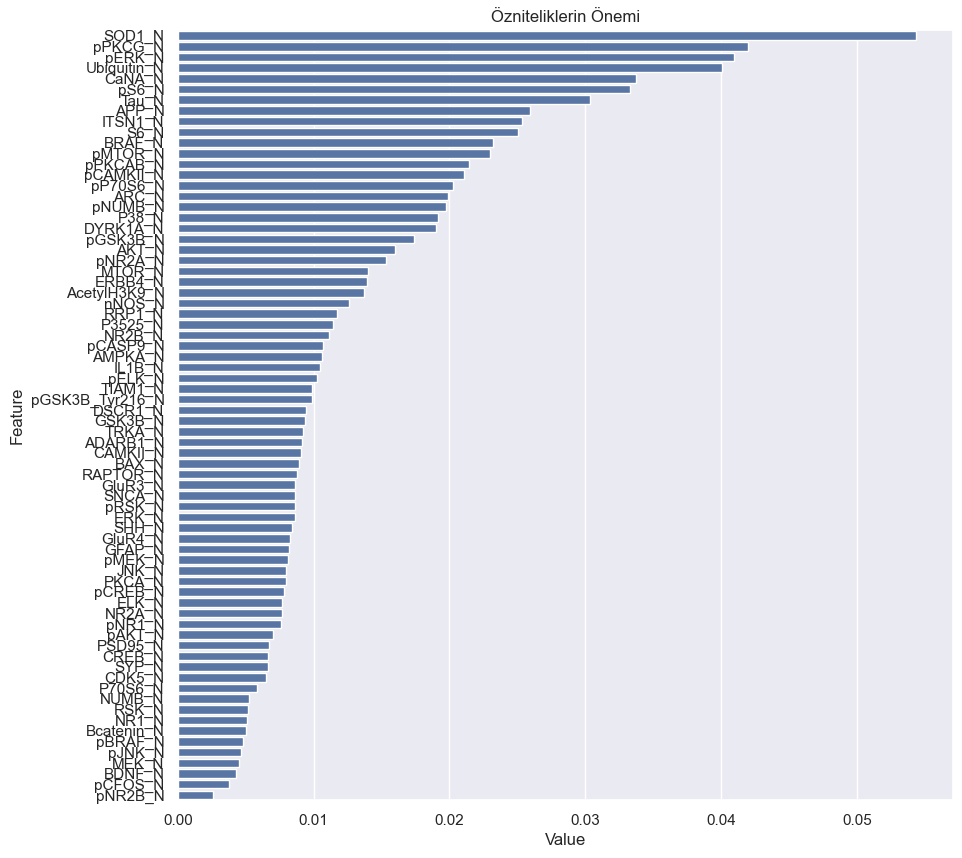

In [32]:
plot_importance(rf_model, X)

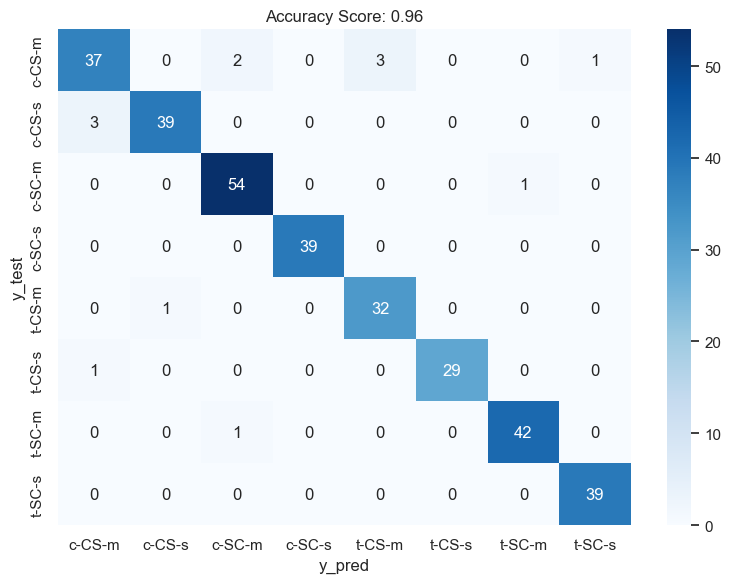

In [33]:
plot_confusion_matrix(y_test, y_pred)

### KNN

In [34]:
knn_model = KNeighborsClassifier(n_neighbors=7).fit(X_train, y_train)
y_pred = knn_model.predict(X_test)

reports["KNN"] = classification_report(y_test, y_pred, output_dict=True)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      c-CS-m       0.89      0.91      0.90        43
      c-CS-s       0.90      0.86      0.88        42
      c-SC-m       1.00      1.00      1.00        55
      c-SC-s       0.97      1.00      0.99        39
      t-CS-m       1.00      0.94      0.97        33
      t-CS-s       0.94      1.00      0.97        30
      t-SC-m       1.00      0.98      0.99        43
      t-SC-s       0.97      1.00      0.99        39

    accuracy                           0.96       324
   macro avg       0.96      0.96      0.96       324
weighted avg       0.96      0.96      0.96       324



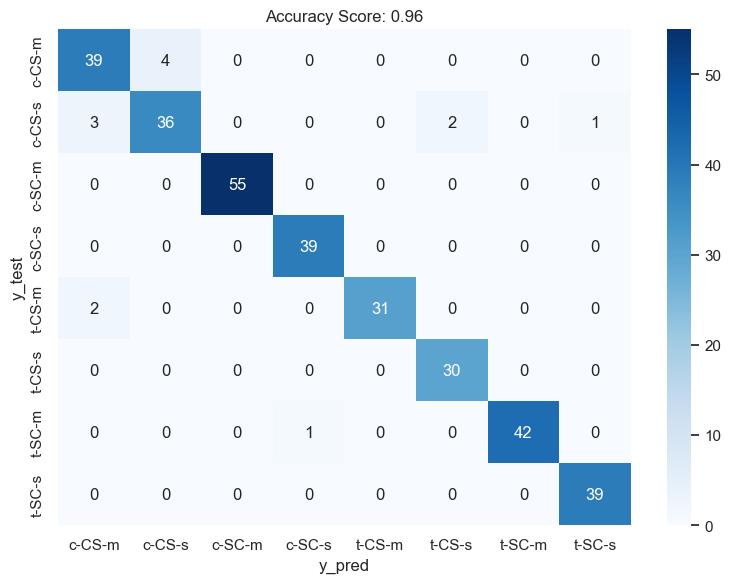

In [35]:
plot_confusion_matrix(y_test, y_pred)

### Logistic Regresyon

In [36]:
log_model = LogisticRegression(max_iter=250).fit(X_train, y_train)
y_pred = log_model.predict(X_test)

reports["Logistic Regression"] = classification_report(y_test, y_pred, output_dict=True)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      c-CS-m       0.80      0.91      0.85        43
      c-CS-s       0.92      0.83      0.88        42
      c-SC-m       1.00      1.00      1.00        55
      c-SC-s       1.00      0.97      0.99        39
      t-CS-m       0.90      0.85      0.88        33
      t-CS-s       1.00      1.00      1.00        30
      t-SC-m       1.00      1.00      1.00        43
      t-SC-s       0.97      1.00      0.99        39

    accuracy                           0.95       324
   macro avg       0.95      0.95      0.95       324
weighted avg       0.95      0.95      0.95       324



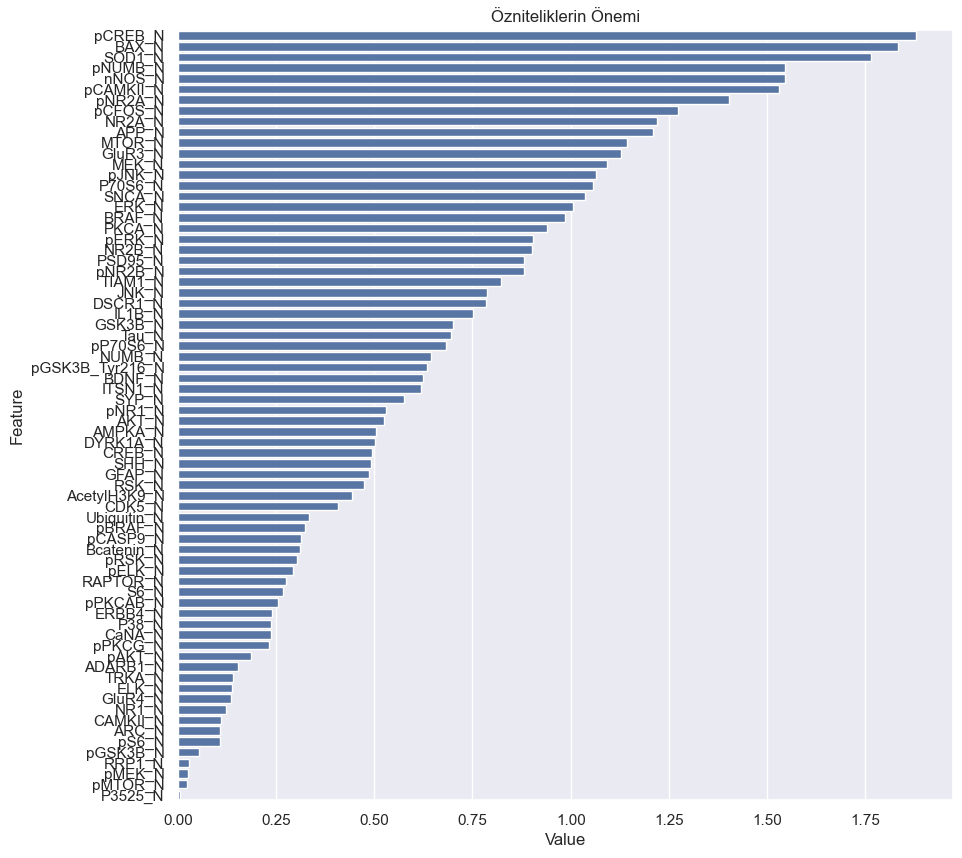

In [37]:
plot_importance(log_model, X)

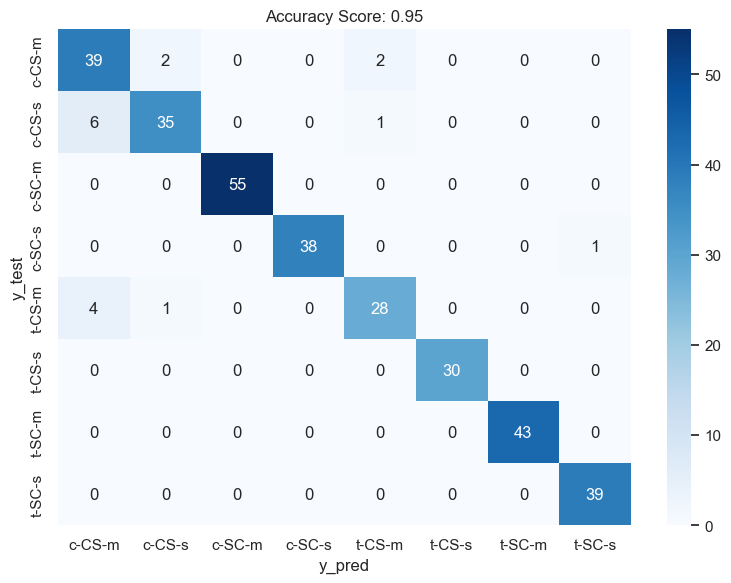

In [38]:
plot_confusion_matrix(y_test, y_pred)

### K-Means

Küme sayısı 8-30 arası değerler arasında denendi ve en iyi sonuç 29'da elde edildi.

In [39]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

kmeans = KMeans(n_clusters=29, random_state=32, n_init='auto')
labels = kmeans.fit_predict(X)

cluster_to_label = {}
for c in np.unique(labels):
    mask = labels == c
    cluster_to_label[c] = mode(y_encoded[mask], keepdims=False).mode

y_pred_encoded = np.array([cluster_to_label.get(c, 0) for c in labels])
y_pred = le.inverse_transform(y_pred_encoded)

reports["KMeans"] = classification_report(y, y_pred, output_dict=True)
print(classification_report(y, y_pred))

              precision    recall  f1-score   support

      c-CS-m       0.77      0.51      0.61       150
      c-CS-s       0.46      0.55      0.50       135
      c-SC-m       0.53      0.63      0.58       150
      c-SC-s       0.52      0.73      0.61       135
      t-CS-m       0.58      0.70      0.64       135
      t-CS-s       0.53      0.52      0.53       105
      t-SC-m       0.63      0.19      0.30       135
      t-SC-s       0.65      0.70      0.68       135

    accuracy                           0.57      1080
   macro avg       0.58      0.57      0.55      1080
weighted avg       0.59      0.57      0.56      1080



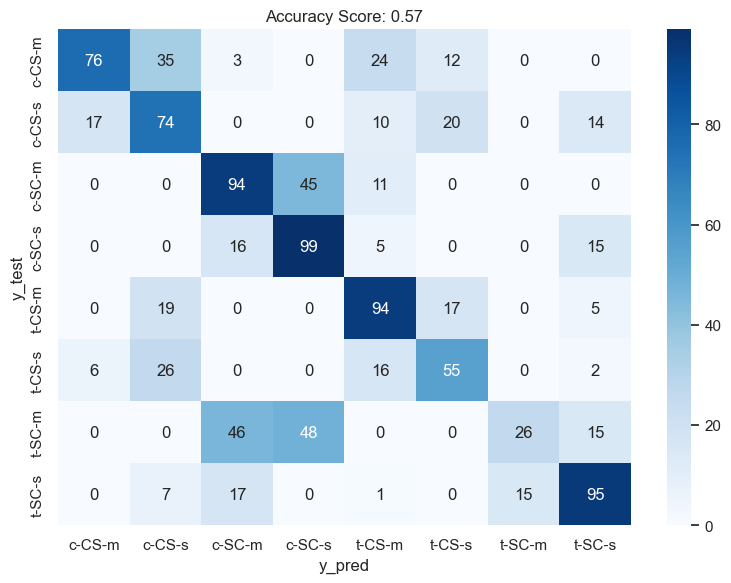

In [40]:
plot_confusion_matrix(y, y_pred)

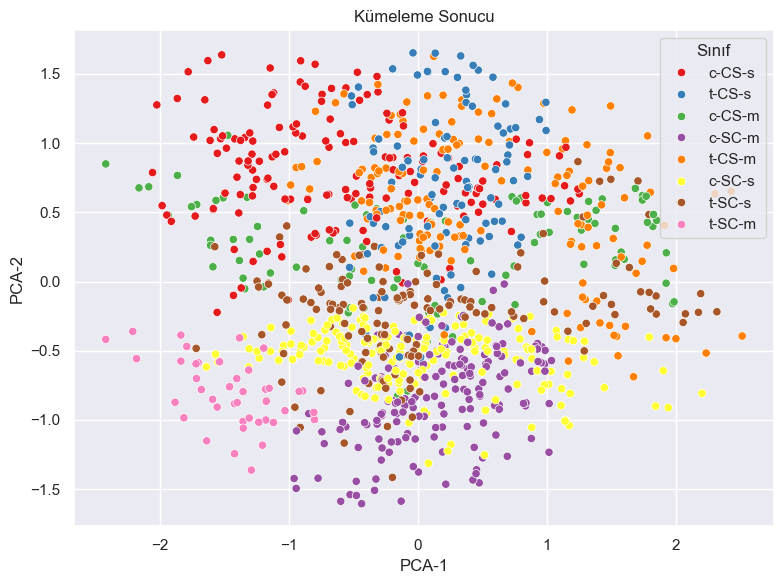

In [41]:
plot_pca_2D(X, y_pred)

### Hiyerarşik Kümeleme

Küme sayısı 8-30 arası değerler arasında denendi ve en iyi sonuç 29'da elde edildi,
Linkage; 'ward', 'complete', 'average', 'single' değerleriyle denendi ve en iyi sonuç 'ward'da elde edildi.

In [42]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

agg_cluster = AgglomerativeClustering(n_clusters=29, linkage="ward")
labels = agg_cluster.fit_predict(X)

cluster_to_label = {}
for c in np.unique(labels):
    mask = labels == c
    cluster_to_label[c] = mode(y_encoded[mask], keepdims=False).mode

y_pred_encoded = np.array([cluster_to_label.get(c, 0) for c in labels])
y_pred = le.inverse_transform(y_pred_encoded)

reports["Agglomerative Clustering"] = classification_report(y, y_pred, output_dict=True)
print(classification_report(y, y_pred))

              precision    recall  f1-score   support

      c-CS-m       0.53      0.80      0.64       150
      c-CS-s       0.67      0.62      0.64       135
      c-SC-m       0.55      0.80      0.65       150
      c-SC-s       0.54      0.44      0.48       135
      t-CS-m       0.64      0.80      0.71       135
      t-CS-s       1.00      0.23      0.37       105
      t-SC-m       0.60      0.33      0.43       135
      t-SC-s       0.78      0.78      0.78       135

    accuracy                           0.62      1080
   macro avg       0.66      0.60      0.59      1080
weighted avg       0.65      0.62      0.60      1080



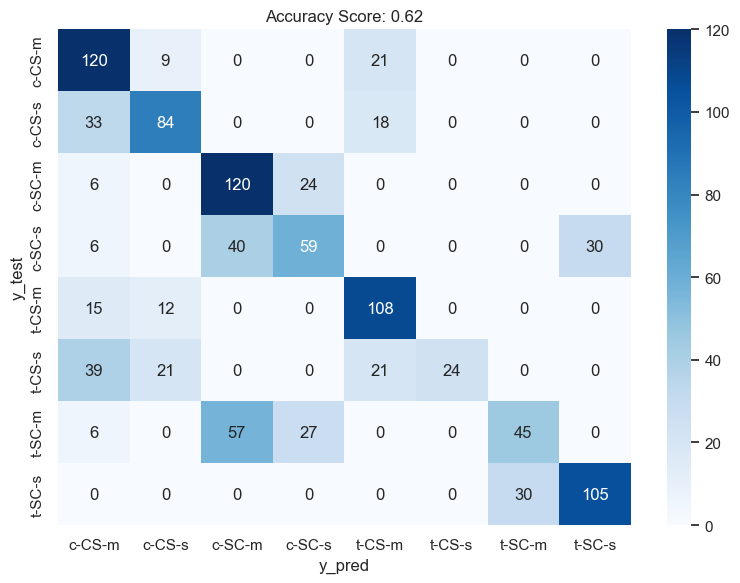

In [43]:
plot_confusion_matrix(y, y_pred)

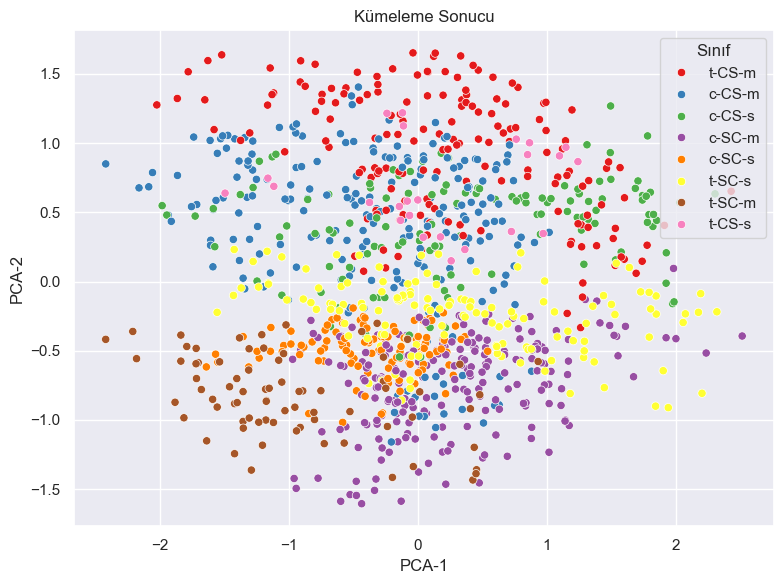

In [44]:
plot_pca_2D(X, y_pred)

### DBSCAN

Epsilon 0.1 - 3.0 araso denendi ve en iyi sonuç 0.80'de elde edildi, min_samples ise 3, 5, 10 değerleriyle denendi ve en iyi sonuç 3 ile elde edildi.

In [45]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

db = DBSCAN(eps=0.80, min_samples=3)
labels = db.fit_predict(X)

unique_clusters = np.unique(labels[labels != -1])

cluster_to_label = {}
for c in unique_clusters:
    mask = labels == c
    cluster_to_label[c] = mode(y_encoded[mask], keepdims=False).mode

y_pred_encoded = np.array([cluster_to_label.get(c, 0) if c != -1 else 0 for c in labels])
y_pred = le.inverse_transform(y_pred_encoded)

reports["DBSCAN"] = classification_report(y, y_pred, output_dict=True)
print(classification_report(y, y_pred))

              precision    recall  f1-score   support

      c-CS-m       0.72      1.00      0.84       150
      c-CS-s       1.00      0.84      0.92       135
      c-SC-m       0.98      0.65      0.78       150
      c-SC-s       0.74      0.97      0.84       135
      t-CS-m       1.00      0.99      1.00       135
      t-CS-s       1.00      0.94      0.97       105
      t-SC-m       0.88      0.78      0.83       135
      t-SC-s       1.00      0.96      0.98       135

    accuracy                           0.89      1080
   macro avg       0.92      0.89      0.89      1080
weighted avg       0.91      0.89      0.89      1080



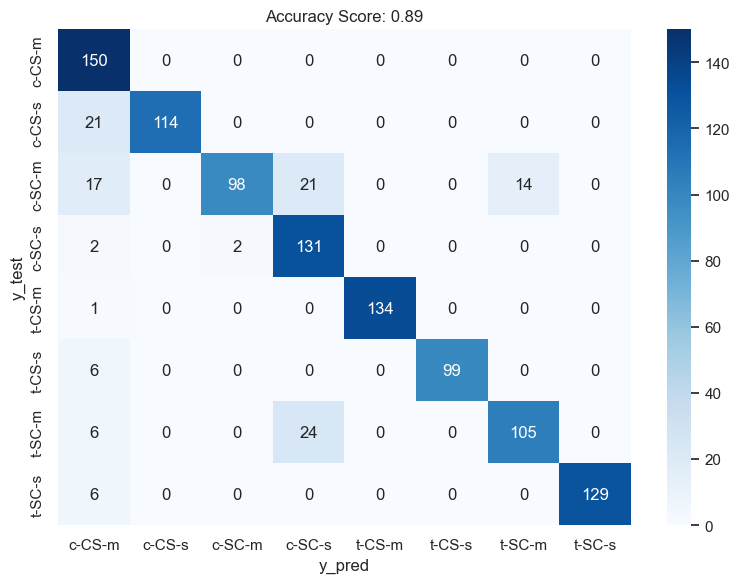

In [46]:
plot_confusion_matrix(y, y_pred)

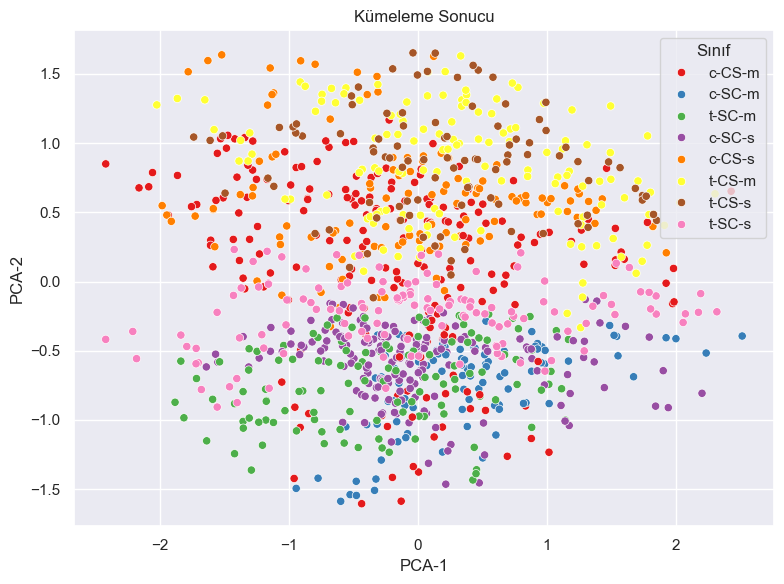

In [47]:
plot_pca_2D(X, y_pred)

## Değerlendirme

In [48]:
reports_df = pd.DataFrame({
    model: {
        'Accuracy': reports[model]['accuracy'],
        'Precision': reports[model]['macro avg']['precision'],
        'Recall': reports[model]['macro avg']['recall'],
        'F1-Score': reports[model]['macro avg']['f1-score']
    }
    for model in reports
}).T

print(reports_df)

                          Accuracy  Precision    Recall  F1-Score
Random Forest             0.959877   0.961355  0.960495  0.960596
KNN                       0.959877   0.959233  0.960032  0.959251
Logistic Regression       0.947531   0.949400  0.945394  0.946523
KMeans                    0.567593   0.584319  0.566402  0.553212
Agglomerative Clustering  0.615741   0.663749  0.599868  0.588822
DBSCAN                    0.888889   0.915547  0.892116  0.893585


Sınıflandırma modelleri arasında en yüksek başarıyı Random Forest göstermiştir. K-Nearest Neighbors modeli de Random Forest ile neredeyse eşdeğer bir performans sergilemiştir. Lojistik regresyon, lineer bir sınıflandırma modeli olmasına rağmen oldukça güçlü bir performans göstermiştir.

Kümeleme algoritmalarına bakıldığında, KMeans modeli en düşük başarıyı göstermiştir. %56 doğruluk oranı ve düşük F1 puanı, bu modelin sınıfların gerçek yapısını doğru şekilde ayırt edemediğini göstermektedir. Hiyerarşik Kümeleme modeli, KMeans'e göre biraz daha başarılıdır. Hiyerarşik yapının, verinin içsel benzerliklerini KMeans’ten daha iyi temsil ettiğini ancak yine de sınıf etiketleriyle tam uyum sağlayamadığını söyleyebiliriz. DBSCAN ise kümeleme algoritmaları arasında açık ara en başarılı model olmuştur. DBSCAN, sınıf yapısının yoğunluk temelli olduğu veri setlerinde ne kadar etkili olabileceğini ortaya koymaktadır. Gürültüye karşı dayanıklılığı ve küme sayısını önceden belirlememe avantajı, bu performansa katkıda bulunmuştur.

Genel olarak değerlendirildiğinde, gözetimli sınıflandırma modelleri doğal olarak daha yüksek başarı sağlamaktadır. Random Forest, KNN ve Logistic Regression gibi modeller etiketli veri ile çalıştıklarından, sınıflar arasındaki farkları doğrudan öğrenme avantajına sahiptir. Buna karşılık kümeleme modelleri, sınıf etiketlerini bilmeden yapı keşfi yaptığı için başarı düzeyi daha düşüktür.

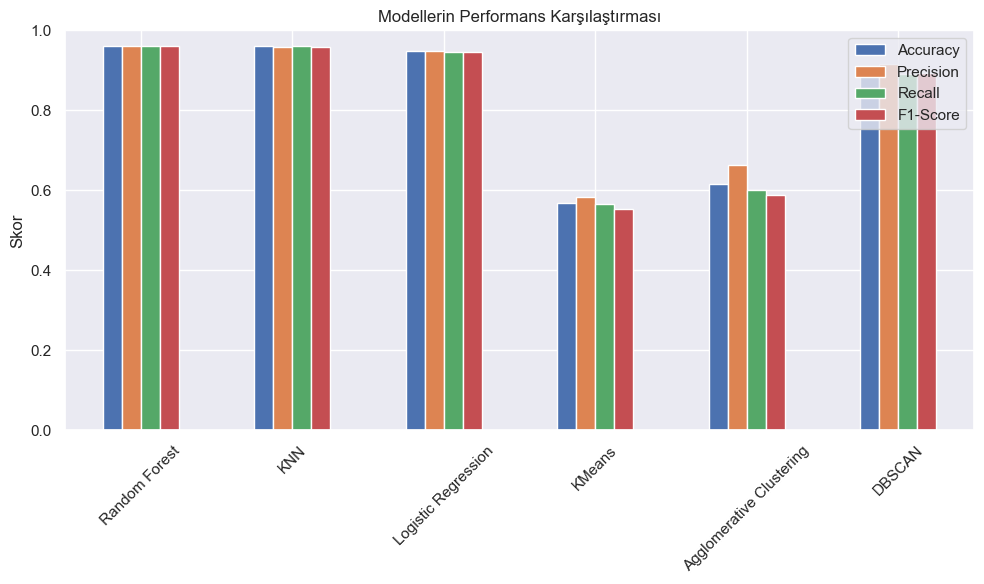

In [49]:
reports_df.plot(kind='bar', figsize=(10, 6))
plt.title("Modellerin Performans Karşılaştırması")
plt.ylabel("Skor")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()